# Handwritten digit classification (MNIST subset, 8k images)

**Questions this notebook answers**
1. How do standard models perform on the flattened pixel data (baseline)?
2. What do **feature extraction / dimensionality reduction** (PCA, HOG, autoencoder codes) add?
3. How do the **training paradigms** compare: supervised, semi-supervised, unsupervised?

Files needed next to this notebook: `ml_utils.py`, `nn_models.py` (PyTorch), and `data/data.csv`.
Protocol: all model *selection* uses 5-fold stratified CV on the training split; the test split is used once,
for the final comparison and for the paradigm comparison.

In [3]:
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC

from ml_utils import (run_all, cv_summary, sweep, plot_sweep, fit_and_test, HOG, AEFeatures,
                      kmeans_cluster_eval, run_label_sweep, label_sweep_table, plot_label_sweep, paired_gain,
                      plot_nn_curves, plot_confusion, top_confusions, plot_misclassified)
from nn_models import (MLP, CNN, DeepEncoder, SemiSupervisedClassifier, train_autoencoder,
                       encode, reconstruct, set_seed)

SEED = 42
DATA_PATH = Path("..") / "data" / "data.csv"

# 1. Data

In [4]:
column_names = ['label'] + [f'x{i}' for i in range(784)]
data = pd.read_csv(DATA_PATH, header=None, names=column_names)
print('raw shape:', data.shape)

raw shape: (8043, 785)


In [5]:
# Cleaning
bad = data[data.isna().any(axis=1)]
print(f'{len(bad)} row(s) with missing pixels at index {bad.index.tolist()} '
      f'({bad.isna().sum(axis=1).tolist()} of 784 pixels missing); last line of file: {bad.index.tolist() == [len(data) - 1]}')
data = data.dropna().reset_index(drop=True)

pixels = data.drop(columns='label').to_numpy()
assert pixels.shape[1] == 784
print('labels:', sorted(data['label'].unique().tolist()))
print('pixel range:', pixels.min(), '-', pixels.max())
print('non-integer pixels:', int((pixels % 1 != 0).sum()), '| blank images:', int((pixels.sum(1) == 0).sum()))
print('duplicate rows:', int(data.duplicated().sum()))

1 row(s) with missing pixels at index [8042] ([409] of 784 pixels missing); last line of file: True
labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pixel range: 0.0 - 255.0
non-integer pixels: 0 | blank images: 0
duplicate rows: 0


8042 images | sparsity (zero pixels): 0.810 | avg. non-zero pixels per image: 149 of 784 | pixels that are 0 in every image: 120


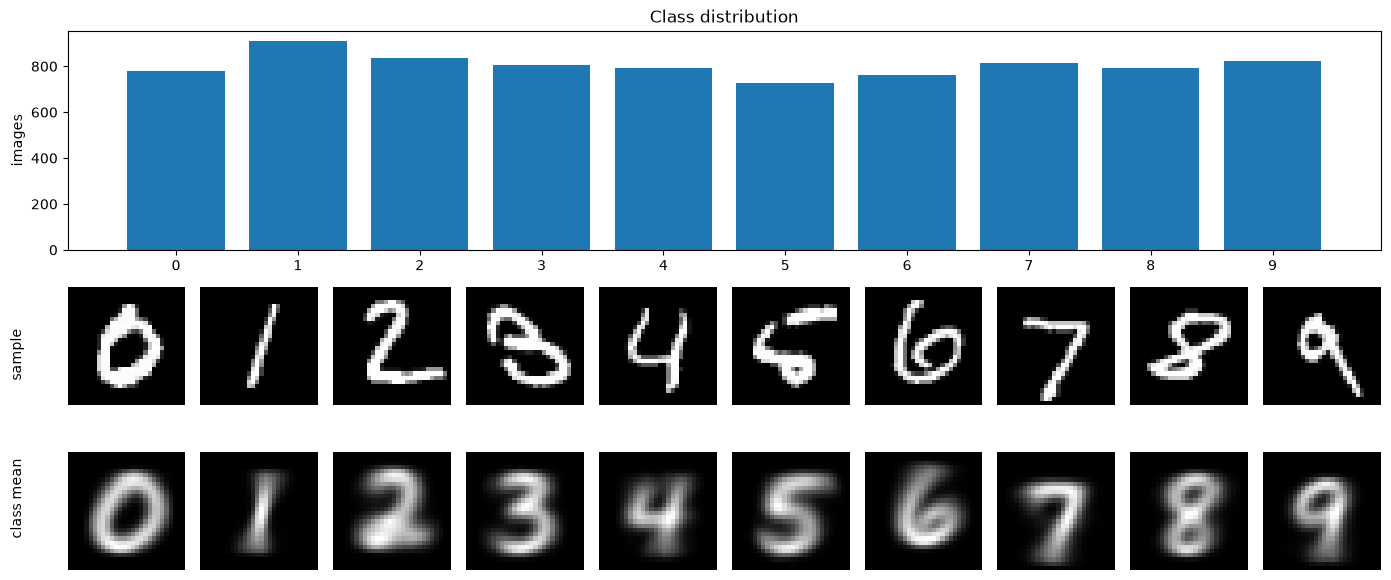

In [6]:
# EDA: class balance, sparsity, example digits and class-mean images
labels = data['label'].to_numpy()
pix = pixels.astype(np.float32)
print(f'{len(data)} images | sparsity (zero pixels): {(pix == 0).mean():.3f} | '
      f'avg. non-zero pixels per image: {(pix > 0).sum(1).mean():.0f} of 784 | '
      f'pixels that are 0 in every image: {int((pix.max(0) == 0).sum())}')

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(3, 10, height_ratios=[1.6, 1, 1])
ax = fig.add_subplot(gs[0, :])
counts = pd.Series(labels).value_counts().sort_index()
ax.bar(counts.index, counts.values); ax.set_xticks(range(10))
ax.set_title('Class distribution'); ax.set_ylabel('images')
for d in range(10):
    idx = np.where(labels == d)[0]
    a = fig.add_subplot(gs[1, d]); a.imshow(pix[idx[0]].reshape(28, 28), cmap='gray'); a.axis('off')
    b = fig.add_subplot(gs[2, d]); b.imshow(pix[idx].mean(0).reshape(28, 28), cmap='gray'); b.axis('off')
fig.text(0.01, 0.40, 'sample', rotation=90, va='center'); fig.text(0.01, 0.16, 'class mean', rotation=90, va='center')
plt.tight_layout(); plt.show()

In [7]:
# Stratified 80/20 split; pixels scaled to [0, 1] (a fixed constant, so no leakage)
x_all = pix / 255.0
y_all = labels.astype(np.int64)
train_idx, test_idx = next(StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(x_all, y_all))
x_train, y_train = x_all[train_idx], y_all[train_idx]
x_test,  y_test  = x_all[test_idx],  y_all[test_idx]

train_hashes = {r.tobytes() for r in x_train}
print(f'train {x_train.shape}, test {x_test.shape}; test images also present in train: '
      f'{sum(r.tobytes() in train_hashes for r in x_test)}')

train (6433, 784), test (1609, 784); test images also present in train: 0


# 2. Baseline models on the flattened pixels

Tune the two hyperparameters that matter most (kNN's `k`, the SVM's `C`) by 5-fold CV, then compare all models.

k=1: acc 0.9361 ± 0.0070
k=3: acc 0.9367 ± 0.0065
k=5: acc 0.9349 ± 0.0052
k=7: acc 0.9363 ± 0.0042
k=11: acc 0.9293 ± 0.0027
k=15: acc 0.9248 ± 0.0047
C=0.5: acc 0.9476 ± 0.0036
C=1: acc 0.9552 ± 0.0018
C=2: acc 0.9596 ± 0.0034
C=5: acc 0.9602 ± 0.0054
C=10: acc 0.9602 ± 0.0047
C=20: acc 0.9600 ± 0.0049
C=50: acc 0.9600 ± 0.0049
selected: k=3, C=5   (differences below one std are ties; prefer the simpler setting)


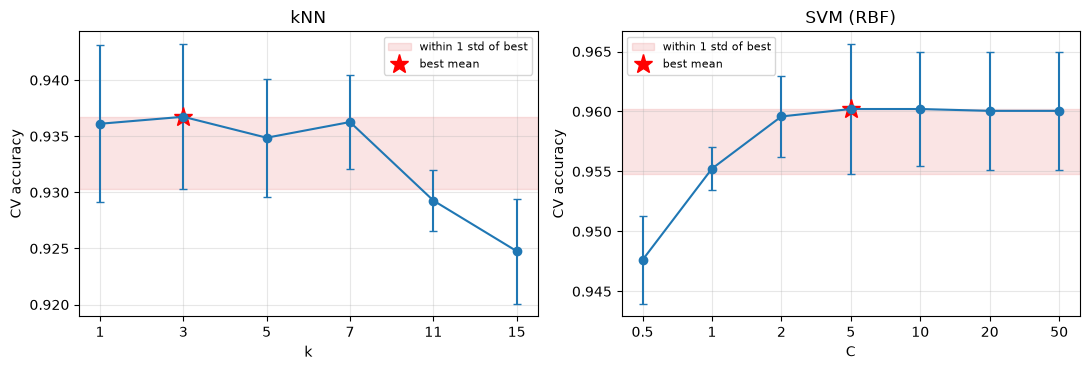

In [8]:
knn_sweep = sweep(lambda k: KNeighborsClassifier(n_neighbors=k), [1, 3, 5, 7, 11, 15], x_train, y_train, 'k', seed=SEED)
svm_sweep = sweep(lambda C: SVC(kernel='rbf', C=C, gamma='scale'), [0.5, 1, 2, 5, 10, 20, 50], x_train, y_train, 'C', seed=SEED)
best_k = int(knn_sweep['acc_mean'].idxmax())
best_C = float(svm_sweep['acc_mean'].idxmax())
print(f'selected: k={best_k}, C={best_C:g}   (differences below one std are ties; prefer the simpler setting)')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
plot_sweep(axes[0], knn_sweep, 'kNN', 'k'); plot_sweep(axes[1], svm_sweep, 'SVM (RBF)', 'C')
plt.tight_layout(); plt.show()

In [9]:
nn_fit = dict(epochs=50, batch_size=64, patience=5)       # early stopping on an inner validation split

baseline_specs = {
    'LogReg':        dict(make_model=lambda: LogisticRegression(max_iter=1000), kind='sklearn'),
    'kNN':           dict(make_model=lambda: KNeighborsClassifier(n_neighbors=best_k), kind='sklearn'),
    'SVM (RBF)':     dict(make_model=lambda: SVC(kernel='rbf', C=best_C, gamma='scale'), kind='sklearn'),
    'Random Forest': dict(make_model=lambda: RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED), kind='sklearn'),
    'MLP':           dict(make_model=lambda: MLP(), kind='nn', fit_kwargs=nn_fit),
    'CNN':           dict(make_model=lambda: CNN(), kind='nn', fit_kwargs=nn_fit),
}
baseline_cv = run_all(baseline_specs, x_train, y_train, n_splits=5, seed=SEED)

[LogReg] fold 1/5: acc=0.8974  macroF1=0.8956  (1.2s)
[LogReg] fold 2/5: acc=0.8936  macroF1=0.8924  (1.2s)
[LogReg] fold 3/5: acc=0.8943  macroF1=0.8927  (1.1s)
[LogReg] fold 4/5: acc=0.8997  macroF1=0.8984  (1.1s)
[LogReg] fold 5/5: acc=0.8896  macroF1=0.8889  (1.0s)
[kNN] fold 1/5: acc=0.9433  macroF1=0.9430  (0.0s)
[kNN] fold 2/5: acc=0.9316  macroF1=0.9316  (0.0s)
[kNN] fold 3/5: acc=0.9293  macroF1=0.9295  (0.0s)
[kNN] fold 4/5: acc=0.9432  macroF1=0.9430  (0.0s)
[kNN] fold 5/5: acc=0.9362  macroF1=0.9370  (0.0s)
[SVM (RBF)] fold 1/5: acc=0.9689  macroF1=0.9685  (2.3s)
[SVM (RBF)] fold 2/5: acc=0.9542  macroF1=0.9540  (2.0s)
[SVM (RBF)] fold 3/5: acc=0.9588  macroF1=0.9584  (2.0s)
[SVM (RBF)] fold 4/5: acc=0.9603  macroF1=0.9598  (2.2s)
[SVM (RBF)] fold 5/5: acc=0.9588  macroF1=0.9587  (2.4s)
[Random Forest] fold 1/5: acc=0.9464  macroF1=0.9456  (1.0s)
[Random Forest] fold 2/5: acc=0.9448  macroF1=0.9445  (0.9s)
[Random Forest] fold 3/5: acc=0.9464  macroF1=0.9461  (0.9s)
[Random

In [10]:
cv_summary(baseline_cv)

,accuracy,macro_f1,fit_time_s
CNN,0.9750 ± 0.0049,0.9750 ± 0.0048,6.1
SVM (RBF),0.9602 ± 0.0054,0.9599 ± 0.0053,2.2
MLP,0.9471 ± 0.0048,0.9467 ± 0.0048,5.3
Random Forest,0.9447 ± 0.0030,0.9442 ± 0.0029,0.9
kNN,0.9367 ± 0.0065,0.9368 ± 0.0063,0.0
LogReg,0.8949 ± 0.0039,0.8936 ± 0.0036,1.1


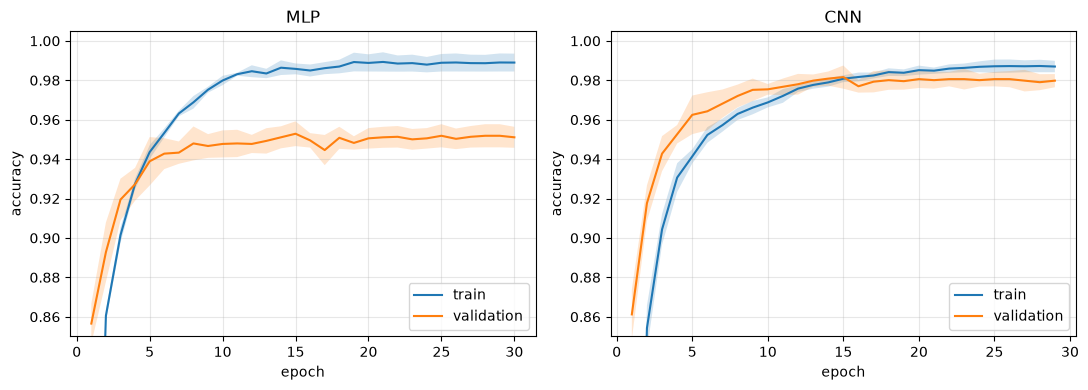

In [11]:
plot_nn_curves(baseline_cv); plt.show()       # mean ± std over folds: is there over-fitting?

# 3. Feature extraction and dimensionality reduction

**Do we need dimensionality reduction?** 784 pixels, but 19% of them are non-zero, and 120 are always zero.

Components for 90% / 95% of the variance: 84 / 147 (of 784)
PCA components=10: acc 0.9246 ± 0.0052
PCA components=20: acc 0.9624 ± 0.0030
PCA components=30: acc 0.9658 ± 0.0034
PCA components=50: acc 0.9681 ± 0.0041
PCA components=100: acc 0.9649 ± 0.0042
PCA components=150: acc 0.9641 ± 0.0041


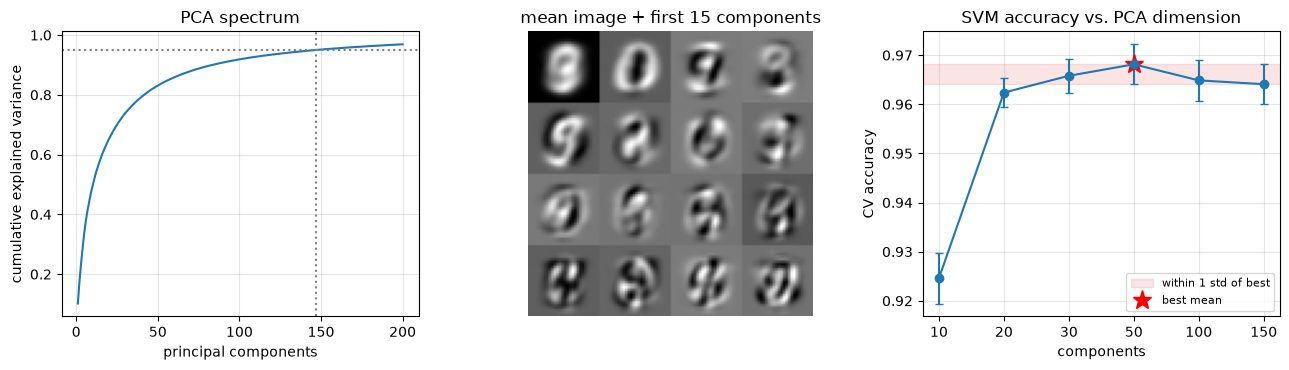

In [12]:
pca_full = PCA(random_state=SEED).fit(x_train)       # unsupervised, descriptive
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95 = [int(np.searchsorted(cum, t) + 1) for t in (0.90, 0.95)]
print(f'Components for 90% / 95% of the variance: {n90} / {n95} (of 784)')

pca_sweep = sweep(lambda n: make_pipeline(PCA(n_components=n, random_state=SEED), SVC(C=best_C, gamma='scale')),
                  [10, 20, 30, 50, 100, 150], x_train, y_train, 'PCA components', seed=SEED)
best_ncomp = int(pca_sweep['acc_mean'].idxmax())

fig = plt.figure(figsize=(13, 3.8))
ax = fig.add_subplot(1, 3, 1); ax.plot(range(1, 201), cum[:200]); ax.grid(alpha=0.3)
ax.axhline(0.95, color='gray', ls=':'); ax.axvline(n95, color='gray', ls=':')
ax.set_xlabel('principal components'); ax.set_ylabel('cumulative explained variance'); ax.set_title('PCA spectrum')
ax = fig.add_subplot(1, 3, 2); ax.axis('off'); ax.set_title('mean image + first 15 components')
canvas = np.zeros((4 * 28, 4 * 28))
for i, t in enumerate([pca_full.mean_] + list(pca_full.components_[:15])):
    r, c = divmod(i, 4); t = np.asarray(t).reshape(28, 28)
    canvas[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = (t - t.min()) / (t.max() - t.min() + 1e-9)
ax.imshow(canvas, cmap='gray')
plot_sweep(fig.add_subplot(1, 3, 3), pca_sweep, 'SVM accuracy vs. PCA dimension', 'components')
plt.tight_layout(); plt.show()

**Unsupervised representation:** a deep autoencoder trained on the training images without labels (also used for the semi-supervised experiment below).

epoch  1/25  reconstruction MSE 0.04931
epoch  5/25  reconstruction MSE 0.01962
epoch 10/25  reconstruction MSE 0.01632
epoch 15/25  reconstruction MSE 0.01498
epoch 20/25  reconstruction MSE 0.01424
epoch 25/25  reconstruction MSE 0.01378
test reconstruction MSE: 0.01154


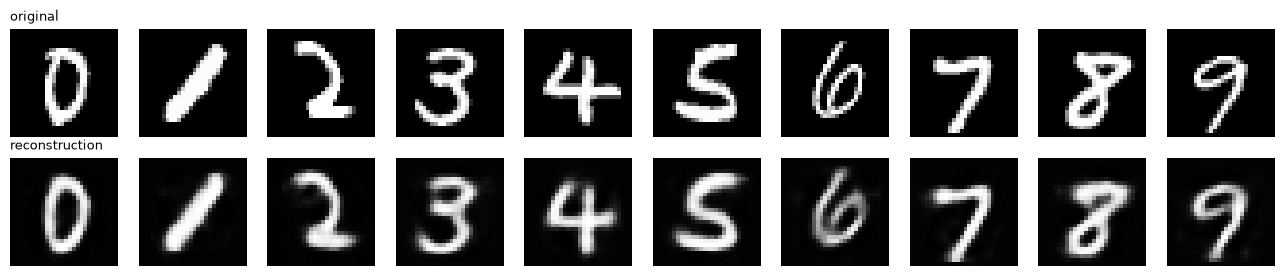

In [13]:
latent_dim = 64
ae, ae_history = train_autoencoder(x_train, latent_dim=latent_dim, seed=SEED)

recon = reconstruct(ae, x_test)
print(f'test reconstruction MSE: {((recon - x_test) ** 2).mean():.5f}')
idx = [np.where(y_test == d)[0][0] for d in range(10)]
fig, axes = plt.subplots(2, 10, figsize=(13, 2.8))
for j, i in enumerate(idx):
    axes[0, j].imshow(x_test[i].reshape(28, 28), cmap='gray'); axes[0, j].axis('off')
    axes[1, j].imshow(recon[i].reshape(28, 28), cmap='gray'); axes[1, j].axis('off')
axes[0, 0].set_title('original', loc='left', fontsize=9); axes[1, 0].set_title('reconstruction', loc='left', fontsize=9)
plt.tight_layout(); plt.show()

**Same classifier (SVM), different representations.** Every extractor is a pipeline step, so it is re-fitted on each
fold's training part only. The autoencoder codes use the Stage-1 autoencoder, which saw the unlabeled training
images (including the held-out fold's images, but never any labels).

In [14]:
svm = lambda: SVC(kernel='rbf', C=best_C, gamma='scale')
feat_specs = {
    f'PCA-{best_ncomp} + SVM': dict(make_model=lambda: make_pipeline(PCA(n_components=best_ncomp, random_state=SEED), svm()), kind='sklearn'),
    'HOG + SVM':               dict(make_model=lambda: make_pipeline(HOG(pixels_per_cell=4), svm()), kind='sklearn'),
    'AE codes + SVM':          dict(make_model=lambda: make_pipeline(AEFeatures(ae.encoder, encode), svm()), kind='sklearn'),
}
feat_cv = run_all(feat_specs, x_train, y_train, n_splits=5, seed=SEED)

# raw pixels + SVM is exactly the baseline SVM (same C, same folds): reuse it instead of recomputing
feature_cv = {'Raw pixels + SVM': baseline_cv['SVM (RBF)'], **feat_cv}
feature_table = cv_summary(feature_cv)
feature_table

[PCA-50 + SVM] fold 1/5: acc=0.9751  macroF1=0.9751  (0.4s)
[PCA-50 + SVM] fold 2/5: acc=0.9650  macroF1=0.9649  (0.4s)
[PCA-50 + SVM] fold 3/5: acc=0.9666  macroF1=0.9663  (0.4s)
[PCA-50 + SVM] fold 4/5: acc=0.9681  macroF1=0.9675  (0.4s)
[PCA-50 + SVM] fold 5/5: acc=0.9658  macroF1=0.9659  (0.4s)
[HOG + SVM] fold 1/5: acc=0.9790  macroF1=0.9789  (7.1s)
[HOG + SVM] fold 2/5: acc=0.9829  macroF1=0.9829  (5.7s)
[HOG + SVM] fold 3/5: acc=0.9790  macroF1=0.9789  (5.6s)
[HOG + SVM] fold 4/5: acc=0.9852  macroF1=0.9852  (6.2s)
[HOG + SVM] fold 5/5: acc=0.9790  macroF1=0.9791  (5.8s)
[AE codes + SVM] fold 1/5: acc=0.9720  macroF1=0.9720  (0.4s)
[AE codes + SVM] fold 2/5: acc=0.9650  macroF1=0.9649  (0.4s)
[AE codes + SVM] fold 3/5: acc=0.9705  macroF1=0.9705  (0.4s)
[AE codes + SVM] fold 4/5: acc=0.9705  macroF1=0.9700  (0.4s)
[AE codes + SVM] fold 5/5: acc=0.9627  macroF1=0.9627  (0.4s)


,accuracy,macro_f1,fit_time_s
HOG + SVM,0.9810 ± 0.0029,0.9810 ± 0.0029,6.1
PCA-50 + SVM,0.9681 ± 0.0041,0.9679 ± 0.0041,0.4
AE codes + SVM,0.9681 ± 0.0040,0.9680 ± 0.0040,0.4
Raw pixels + SVM,0.9602 ± 0.0054,0.9599 ± 0.0053,2.2


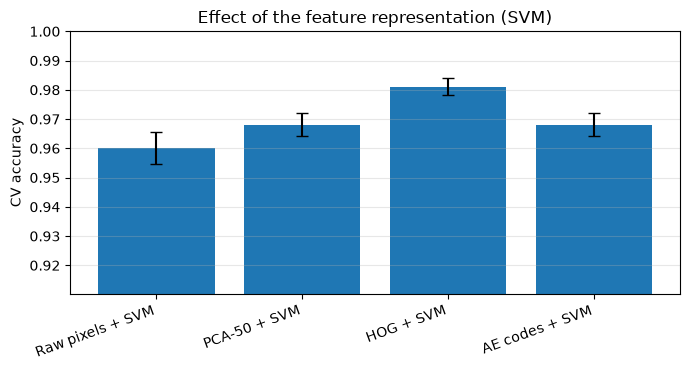

In [15]:
accs = {n: r['folds']['accuracy'] for n, r in feature_cv.items()}
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(list(accs), [a.mean() for a in accs.values()], yerr=[a.std() for a in accs.values()], capsize=4)
ax.set_ylim(min(a.mean() for a in accs.values()) - 0.05, 1.0)
ax.set_ylabel('CV accuracy'); ax.set_title('Effect of the feature representation (SVM)'); ax.grid(alpha=0.3, axis='y')
plt.xticks(rotation=20, ha='right'); plt.tight_layout(); plt.show()

# 4. Training paradigms: unsupervised, semi-supervised, supervised

| paradigm | labels used | model |
|---|---|---|
| unsupervised | none for training; training labels only to name the clusters | k-means on pixels / PCA / autoencoder codes |
| semi-supervised | all images unlabeled for pretraining + a small labeled fraction | autoencoder encoder + classification head |
| supervised | the labeled fraction (or all labels) only | same network from scratch, and an SVM |

In [16]:
# Unsupervised: k-means with 10 clusters. Each cluster is named after the majority label of its TRAINING images.
pca_km = PCA(n_components=best_ncomp, random_state=SEED).fit(x_train)
spaces = {
    'pixels':                  (x_train, x_test),
    f'PCA-{best_ncomp}':       (pca_km.transform(x_train), pca_km.transform(x_test)),
    'AE codes':                (encode(ae.encoder, x_train), encode(ae.encoder, x_test)),
}
km_table = pd.DataFrame({name: kmeans_cluster_eval(Ztr, y_train, Zte, y_test, seed=SEED)
                         for name, (Ztr, Zte) in spaces.items()}).T
km_table.round(4)

,accuracy,macro_precision,macro_recall,macro_f1,NMI,ARI
pixels,0.5867,0.5463,0.5769,0.5534,0.4913,0.3594
PCA-50,0.5830,0.5424,0.5731,0.5501,0.4896,0.3562
AE codes,0.5314,0.4689,0.5224,0.4816,0.4700,0.3244


In [17]:
# Supervised vs. semi-supervised as the number of labels grows (3 seeds per labeled subset)
semi_fit = dict(epochs=100, batch_size=32, patience=10)
nn_variants = {
    'NN from scratch (supervised)': lambda: SemiSupervisedClassifier(DeepEncoder(latent_dim), latent_dim),
    'AE-pretrained NN (semi-supervised)': lambda: SemiSupervisedClassifier(copy.deepcopy(ae.encoder), latent_dim),
}
references = {'SVM on pixels (supervised)': lambda: SVC(kernel='rbf', C=best_C, gamma='scale')}

label_fracs = [0.02, 0.05, 0.10, 0.25, 1.0]
semi_df = run_label_sweep(x_train, y_train, x_test, y_test, label_fracs, seeds=[0, 1, 2],
                          nn_variants=nn_variants, references=references, fit_kwargs=semi_fit, seed_fn=set_seed)

done: 128 labels (2%), seed 0
done: 128 labels (2%), seed 1
done: 128 labels (2%), seed 2
done: 321 labels (5%), seed 0
done: 321 labels (5%), seed 1
done: 321 labels (5%), seed 2
done: 643 labels (10%), seed 0
done: 643 labels (10%), seed 1
done: 643 labels (10%), seed 2
done: 1608 labels (25%), seed 0
done: 1608 labels (25%), seed 1
done: 1608 labels (25%), seed 2
done: 6433 labels (100%), seed 0
done: 6433 labels (100%), seed 1
done: 6433 labels (100%), seed 2


In [18]:
print('Test accuracy (mean ± std over seeds); columns = number of labeled training images')
label_sweep_table(semi_df)

Test accuracy (mean ± std over seeds); columns = number of labeled training images


n_labels,128,321,643,1608,6433
method,,,,,
AE-pretrained NN (semi-supervised),0.756 ± 0.027,0.834 ± 0.037,0.885 ± 0.004,0.915 ± 0.005,0.959 ± 0.003
NN from scratch (supervised),0.764 ± 0.022,0.847 ± 0.014,0.874 ± 0.020,0.916 ± 0.006,0.959 ± 0.004
SVM on pixels (supervised),0.811 ± 0.019,0.876 ± 0.009,0.910 ± 0.003,0.937 ± 0.005,0.963 ± 0.000


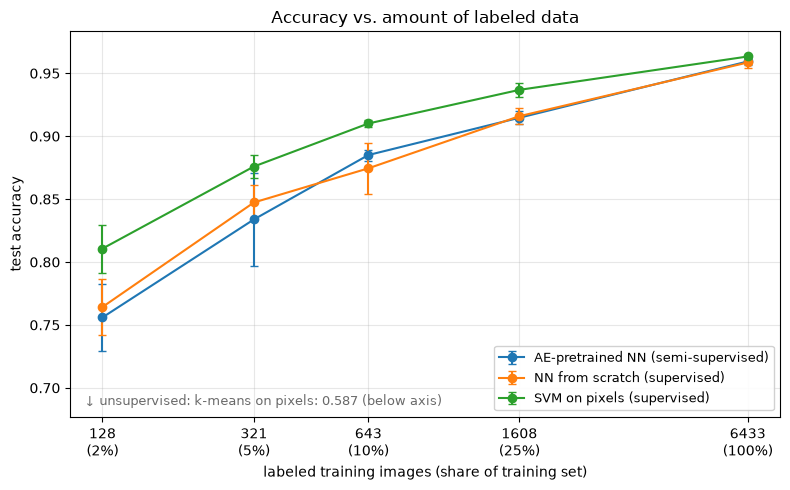

Paired accuracy gain of pretraining (compare the mean with the std across seeds):


,mean,std
label_frac,,
0.02,-0.0083,0.0052
0.05,-0.0135,0.0255
0.10,0.0106,0.0200
0.25,-0.0012,0.0069
1.00,0.0008,0.0020


In [19]:
best_km = km_table['accuracy'].idxmax()
plot_label_sweep(semi_df, hlines={f'unsupervised: k-means on {best_km}': km_table.loc[best_km, 'accuracy']})
plt.tight_layout(); plt.show()

print('Paired accuracy gain of pretraining (compare the mean with the std across seeds):')
paired_gain(semi_df, 'AE-pretrained NN (semi-supervised)', 'NN from scratch (supervised)')

# 5. Final test-set evaluation and error analysis

Finalists are chosen from the **CV leaderboard** (top 3 + the best neural network), then evaluated once on the test set.

In [20]:
all_specs = {**baseline_specs, **feat_specs}
all_cv = {**baseline_cv, **feat_cv}
leaderboard = cv_summary(all_cv)          # sorted by CV accuracy
print('CV leaderboard (5-fold, training split only)')
leaderboard

CV leaderboard (5-fold, training split only)


,accuracy,macro_f1,fit_time_s
HOG + SVM,0.9810 ± 0.0029,0.9810 ± 0.0029,6.1
CNN,0.9750 ± 0.0049,0.9750 ± 0.0048,6.1
PCA-50 + SVM,0.9681 ± 0.0041,0.9679 ± 0.0041,0.4
AE codes + SVM,0.9681 ± 0.0040,0.9680 ± 0.0040,0.4
SVM (RBF),0.9602 ± 0.0054,0.9599 ± 0.0053,2.2
MLP,0.9471 ± 0.0048,0.9467 ± 0.0048,5.3
Random Forest,0.9447 ± 0.0030,0.9442 ± 0.0029,0.9
kNN,0.9367 ± 0.0065,0.9368 ± 0.0063,0.0
LogReg,0.8949 ± 0.0039,0.8936 ± 0.0036,1.1


In [21]:
ranking = list(leaderboard.index)
nn_names = [n for n, s in all_specs.items() if s['kind'] == 'nn']
best_nn = max(nn_names, key=lambda n: all_cv[n]['folds']['accuracy'].mean())
finalists = list(dict.fromkeys(ranking[:3] + [best_nn]))
print('finalists:', finalists)

final = {n: fit_and_test(n, all_specs[n], x_train, y_train, x_test, y_test, seed=SEED) for n in finalists}
test_table = pd.DataFrame({n: f['row'] for n, f in final.items()}).T.astype(float).sort_values('macro_f1', ascending=False)
test_table.round({'accuracy': 4, 'macro_precision': 4, 'macro_recall': 4, 'macro_f1': 4,
                  'fit_time_s': 2, 'predict_ms_per_img': 3})

finalists: ['HOG + SVM', 'CNN', 'PCA-50 + SVM']


,accuracy,macro_precision,macro_recall,macro_f1,fit_time_s,predict_ms_per_img,n_params
HOG + SVM,0.9820,0.9820,0.9819,0.9819,12.18,3.214,3629250.0
CNN,0.9770,0.9773,0.9768,0.9770,5.15,0.012,206922.0
PCA-50 + SVM,0.9671,0.9671,0.9667,0.9668,0.86,0.203,184933.0


Best model on the test set: HOG + SVM
              precision    recall  f1-score   support

           0      0.994     0.994     0.994       156
           1      0.989     0.984     0.986       182
           2      0.994     0.994     0.994       168
           3      0.970     0.988     0.979       162
           4      0.981     0.975     0.978       158
           5      0.986     0.972     0.979       145
           6      0.980     0.987     0.984       152
           7      0.976     0.982     0.979       163
           8      0.981     0.981     0.981       158
           9      0.970     0.964     0.967       165

    accuracy                          0.982      1609
   macro avg      0.982     0.982     0.982      1609
weighted avg      0.982     0.982     0.982      1609



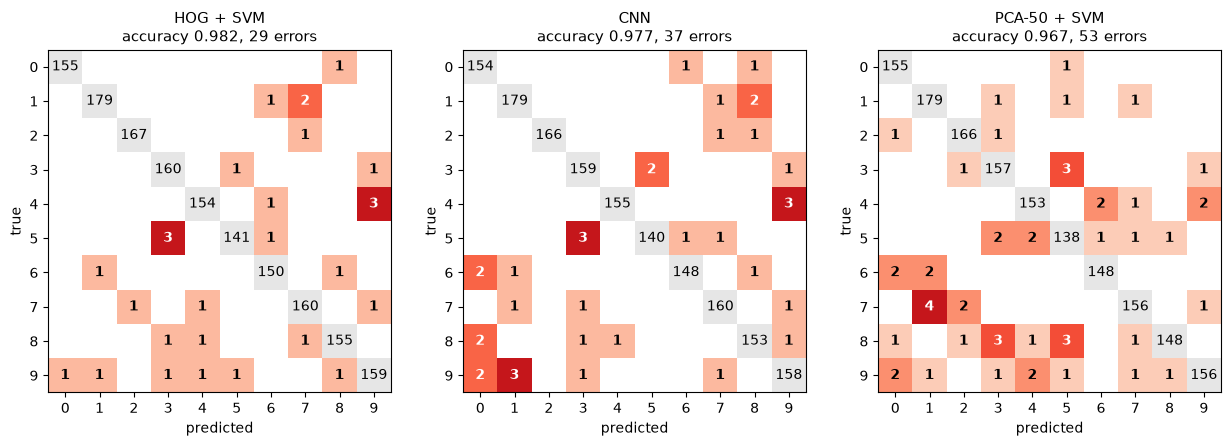

In [22]:
focus = test_table.index[0]
y_pred = final[focus]['y_pred']
print(f'Best model on the test set: {focus}')
print(classification_report(y_test, y_pred, digits=3))

fig, axes = plt.subplots(1, len(final), figsize=(4.2 * len(final), 4.2), squeeze=False)
for ax, (n, f) in zip(axes[0], final.items()):
    plot_confusion(y_test, f['y_pred'], n, ax)
plt.tight_layout(); plt.show()

In [23]:
confusions = top_confusions(y_test, y_pred)
confusions

,true,predicted,count,% of true class
0,4,9,3,1.9
1,5,3,3,2.1
2,1,7,2,1.1
3,0,8,1,0.6
4,1,6,1,0.5
5,2,7,1,0.6


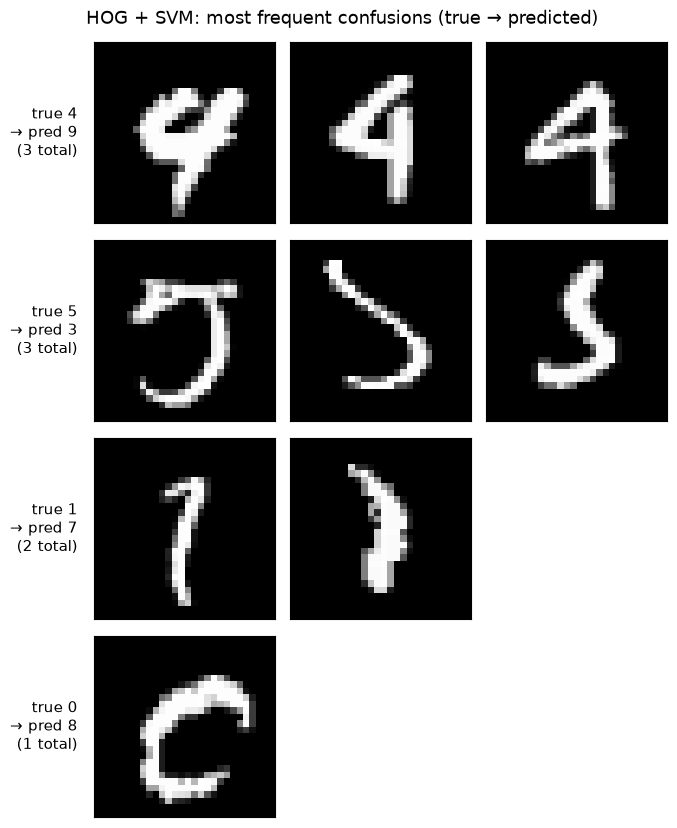

In [24]:
plot_misclassified(x_test, y_test, y_pred, list(zip(confusions['true'][:4], confusions['predicted'][:4])),
                   title=f'{focus}: most frequent confusions (true → predicted)')

### Summary across paradigms and representations

In [25]:
# ten = semi_df[np.isclose(semi_df['label_frac'], 0.10)].groupby('method')['accuracy'].agg(['mean', 'std'])
# n10 = int(semi_df.loc[np.isclose(semi_df['label_frac'], 0.10), 'n_labels'].iloc[0])
# summary = pd.DataFrame([
#     {'paradigm': 'supervised, all labels',              'model': focus,                                     'test accuracy': test_table.loc[focus, 'accuracy']},
#     {'paradigm': f'supervised, {n10} labels',           'model': 'NN from scratch',                         'test accuracy': ten.loc['NN from scratch (supervised)', 'mean']},
#     {'paradigm': f'semi-supervised, {n10} labels',      'model': 'AE-pretrained NN',                        'test accuracy': ten.loc['AE-pretrained NN (semi-supervised)', 'mean']},
#     {'paradigm': 'unsupervised (clusters named by labels)', 'model': f'k-means on {best_km}',                'test accuracy': km_table.loc[best_km, 'accuracy']},
# ]).set_index('paradigm')
# summary.round(4)

# Using full 60k MNIST data

In [26]:
# models

models = {
    'CNN' : dict(make_model=lambda: CNN(), kind='nn', fit_kwargs=nn_fit),
    'kNN' : dict(make_model=lambda: KNeighborsClassifier(n_neighbors=best_k), kind='sklearn'),
    'SVM' : dict(make_model=lambda: SVC(kernel='rbf', C=best_C, gamma='scale'), kind='sklearn'),
    'HOG + SVM': dict(make_model=lambda: make_pipeline(HOG(pixels_per_cell=4), SVC(kernel='rbf', C=best_C, gamma='scale')), kind='sklearn'),
}


### CNN

### kNN

### SVM